In [1]:
import pandas as pd 

In [2]:
df = pd.read_csv("/Users/thas/Desktop/stadioequities_churn_extract(in).csv")

In [3]:
print(df.shape)

(24891, 15)


In [4]:
df.head()

,account_id,account_type,registration_date,funding_status,dormancy_flag,last_login_date,number_of_trades_first_6_months,deposit_amount_cents,province,acquisition_channel,age,gender,risk_appetite,support_tickets,feedback_rating
0,ACC31537,Premium,9/11/2025 2:01,Funded,0,15-08-2026 06:12:24,27,1000000.0,KZN,Email Campaign,51.0,Female,High,0,5.0
1,ACC32173,Retail,9/5/2023 6:14,Not Funded,1,19-05-2023 02:53:29,0,0.0,LP,Influencer,21.0,Female,High,0,NaN
2,ACC33227,Retail,29-06-2025 15:06:15,Funded,0,23-08-2026 13:02:38,6,290361.0,GP,Online Ad,35.0,Female,Moderate,2,5.0
3,ACC11549,Premium,24-02-2026 10:16:10,Not Funded,1,23-05-2026 01:07:58,0,0.0,NC,Radio,35.0,Male,Moderate,2,NaN
4,ACC22061,Retail,2/1/2024 23:09,Funded,0,14-08-2026 12:02:00,8,974942.0,KZN,Referral,51.0,Male,High,1,3.0


In [5]:
df["churn"] = (
    (df["dormancy_flag"] == 1) &
    (df["number_of_trades_first_6_months"] == 0)
).astype(int)

The churn label creation

The original dataset did not contain a target variable indicating whether a customer had churned. Therefore, a churn label was created based on business rules provided in the dataset.

Customers were classified as churned if they were marked as dormant and had completed zero trades within their first siz months. Customers meeting both conditions were assigned a value of 1 (Churn), while all other customers were assigned a value of 0(Non-Churn).

This target variable will be used for machine learning classification.

In [6]:
print("Dataset Shape:", df.shape)

print("\nClass Distribution:")
print(df["churn"].value_counts())

print("\nClass Proportions (%):")
print(df["churn"].value_counts(normalize=True) * 100)

Dataset Shape: (24891, 16)

Class Distribution:
churn
0    17433
1     7458
Name: count, dtype: int64

Class Proportions (%):
churn
0    70.037363
1    29.962637
Name: proportion, dtype: float64


The dataset was explored to determine the number of records available for analysis and to understand the distribution of churned and non-churned customers. 

Understanding the class distribution is important because heavily imbalanced datasets can negatively affect model performance.

In [7]:
df.info()

df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24891 entries, 0 to 24890
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   account_id                       24891 non-null  object 
 1   account_type                     24891 non-null  object 
 2   registration_date                24891 non-null  object 
 3   funding_status                   24891 non-null  object 
 4   dormancy_flag                    24891 non-null  int64  
 5   last_login_date                  24548 non-null  object 
 6   number_of_trades_first_6_months  24891 non-null  int64  
 7   deposit_amount_cents             24891 non-null  float64
 8   province                         24891 non-null  object 
 9   acquisition_channel              24891 non-null  object 
 10  age                              24742 non-null  float64
 11  gender                           23931 non-null  object 
 12  risk_appetite     

account_id                            0
account_type                          0
registration_date                     0
funding_status                        0
dormancy_flag                         0
last_login_date                     343
number_of_trades_first_6_months       0
deposit_amount_cents                  0
province                              0
acquisition_channel                   0
age                                 149
gender                              960
risk_appetite                         0
support_tickets                       0
feedback_rating                    7009
churn                                 0
dtype: int64

The structure of the dataset was examined to identify data types and determine which variables contained missing values.
This step helps ensure appropriate preprocessing techniques are applied before model development.

In [8]:
df["age"] = df["age"].fillna(
    df["age"].median()
)

df["feedback_rating"] = df["feedback_rating"].fillna(
    df["feedback_rating"].median()
)

df["gender"] = df["gender"].fillna(
    "Unknown"
)

Missing values were identified and treated to prevent errors during the model training. 
Numerical variables were imputed using the median value because the median is less sensitive to outliers than the mean. Missing categorical values were replaced with "Unknown" to preserve observations that may still contain useful information.

In [9]:
df["registration_date"] = pd.to_datetime(
    df["registration_date"],
    errors="coerce"
)

df["last_login_date"] = pd.to_datetime(
    df["last_login_date"],
    errors="coerce",
    dayfirst=True
)

Date variables were converted from text format into datetime format.
This transformation allows useful information to be extracted from dates and ensures that the dataset can be processed correctly by the machince learning model.

In [10]:
df["registration_year"] = (
    df["registration_date"].dt.year
)

df["registration_month"] = (
    df["registration_date"].dt.month
) 

df["last_login_year"] = (
    df["last_login_date"].dt.year
)

df["last_login_month"] = (
    df["last_login_date"].dt.month
)

Additional features were created from the registration and login dates. 
The year and month components were extracted because they may provide useful patterns related to customer behaviour and account activity, which could influence churn.

In [11]:
df.drop(
    [
        "account_id",
        "registration_date",
        "last_login_date",
        "dormancy_flag",
        "number_of_trades_first_6_months"
    ],
    axis=1,
    inplace=True
)

Several columns were removed before model training.
The account identifier was removed because it does not contribute predictive value.
The original date fields were removed after feature extraction because the relevant information had already been captured in the newly engineered variables.
The dormancy and trading activity variables used to create the churn label were also removed to prevent target leakage. Keeping these variables would allow the model to indirectly see the answer during training and produce unrealistic results.

In [12]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

cat_cols = [
    "account_type",
    "funding_status",
    "province",
    "acquisition_channel",
    "gender",
    "risk_appetite"
]

for col in cat_cols:
    df[col] = le.fit_transform(df[col])

Machine learning algorithms require numerical inputs.
Categorical variables such as account type, funding status, province, acquisition channel, gender and risk appetite were converted into numerical values using Label Encoding.
This process allows the Random Forest model to use categorical information during training. 

In [13]:
X = df.drop("churn", axis=1)

y = df["churn"]

The dataset was divided into predictor variables (X) and the target variable (y).
The predictor variables contain customer characteristics and behavioural information, while the target variable represents whether a customer churned or not.

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

The dataset was split into training, validation and testing datasets.
The training dataset was used to train the machine learning model, the validation dataset was used to assess performance during development and the testing dataset was reserved for the final evaluation of the model on the unseen data. 
A stratified split was applied to perserve the original churn class distribution across all datasets.

In [15]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


A Random Forest Classifier was selected for churn prediction.
Random Forest is an ensemble learning technique that combines multiple decision trees to improve predictive accuracy and reduce overfitting. 
The model was configured with 100 estimators to ensure stable predictions while maintaining reasonable computational efficiency. A random state of 42 was used to ensure reproducible results.

In [16]:
from sklearn.metrics import(
   accuracy_score,
   classification_report,
   confusion_matrix
)

val_pred = model.predict(X_val)

print(
    "Validation Accuracy:",
    accuracy_score(y_val, val_pred)
)

print(
    classification_report(
        y_val,
        val_pred
    )
)

Validation Accuracy: 0.963310123192287
              precision    recall  f1-score   support

           0       0.98      0.96      0.97      2615
           1       0.92      0.96      0.94      1119

    accuracy                           0.96      3734
   macro avg       0.95      0.96      0.96      3734
weighted avg       0.96      0.96      0.96      3734



The validation dataset was used to evaluate model performance on unseen data after training.
Validation helps assess whether the model has learned meaningful patterns and can generalise beyond the training dataset.

In [17]:
y_pred = model.predict(X_test)

print(
    "Test Accuracy:",
    accuracy_score(y_test, y_pred)
)

print(
    classification_report(
        y_test,
        y_pred
    )
)

Test Accuracy: 0.9670594536689877
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      2615
           1       0.93      0.96      0.95      1119

    accuracy                           0.97      3734
   macro avg       0.96      0.96      0.96      3734
weighted avg       0.97      0.97      0.97      3734



Several evaluation metrics were calculated to assess predictive performance.
Accuracy measures the overall correctness, precision measures the proportion of predicted churn cases that were correct, recall measures the model's ability to identify actual churn cases and the F1-score provides a balance between precision and recall.

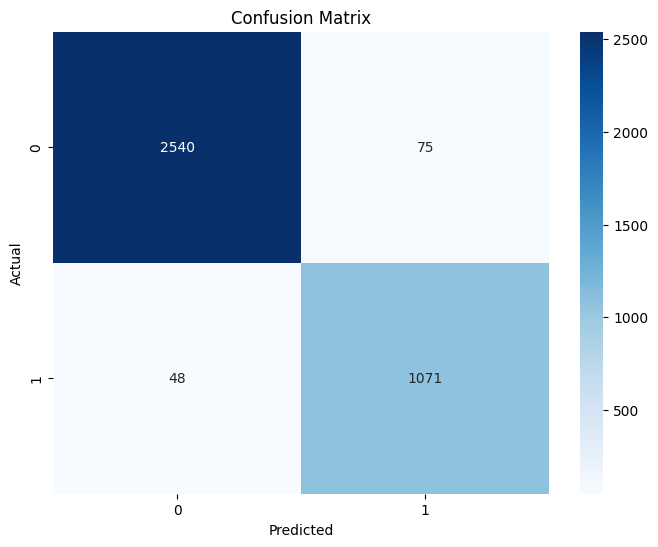

In [18]:
import matplotlib.pyplot as plt 
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

A confusion matrix was generated to visualise the prediction outcomes.
The visualisation provides detailed insight into correct and incorrect classifications, allowing assessment of both successful churn predictions and prediction errors.

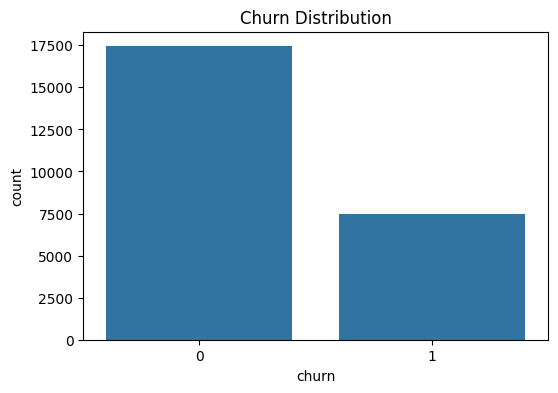

In [19]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="churn",
    data=df
)

plt.title("Churn Distribution")

plt.show()

The distribution of churned and non-churned customers was visualised using a count plot.
This graph provides a clear overview of the target variable and highlights the balance between classes within the dataset.

In [20]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
)

feature_importance = feature_importance.sort_values(
    ascending=False
)

Feature importance scores were calculated to determine which variables have the strongest influence on churn prediction.
Understanding the most influential features can help STADIOEquities identify key customer behaviours and characteristics associated with customer churn.

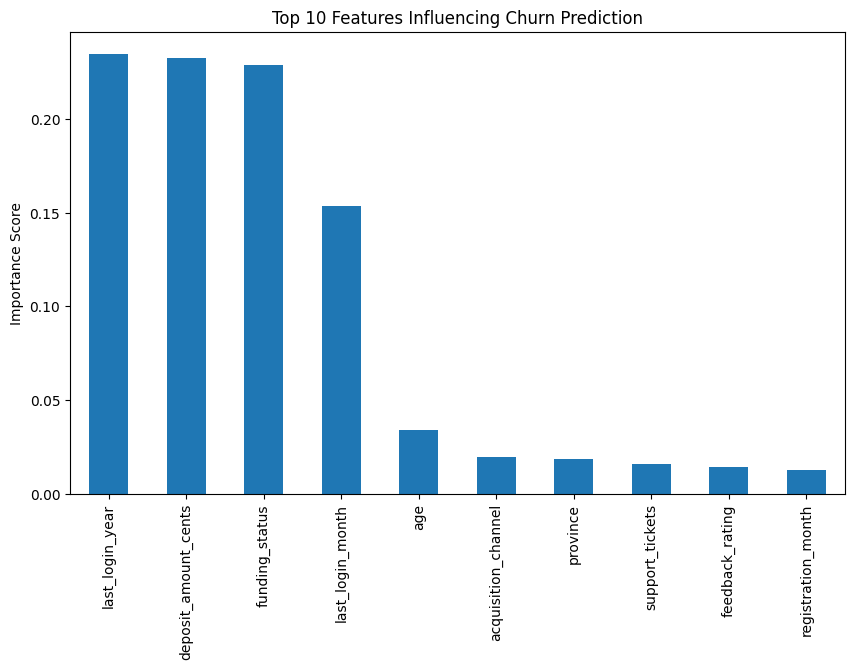

In [21]:
plt.figure(figsize=(10,6))

feature_importance.head(10).plot(
    kind="bar"
)

plt.title(
    "Top 10 Features Influencing Churn Prediction"
)

plt.ylabel(
    "Importance Score"
)

plt.show()

The top ten most important features were visualised using a bar chart.
This visualisation highlights the factors that contributed most strongly to the model's predictions and provides actionable insights that may support customer retention strategies.